<a href="https://colab.research.google.com/github/Arya-rb/Arya-customer-churn-prediction/blob/main/Arya_dataset_customer_churn_cleaned_logistic_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
file_path="/content/drive/MyDrive/AI_ ML_Class_Works/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [9]:
df=pd.read_csv(file_path)

In [10]:
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",None)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [15]:
#Convert TotalCharges  to numerical its in object
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [16]:
df['TotalCharges'].dtype

dtype('float64')

In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [18]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df=df.drop_duplicates()

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.isna().mean()*100 # need to handle total charges missing values

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


In [23]:
df=df.drop(columns=["customerID"],errors='ignore') #drop customer id

In [24]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [25]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [26]:
X=df.drop(columns=["Churn"],axis=1)
y=df["Churn"]

In [27]:
y.value_counts()
y.value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [29]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",X_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409, 19)


### Additional split: create a validation set



The validation set is used to select K and the Logistic Regression threshold. The test set is kept for final evaluation only.

In [30]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (4225, 19) (4225,)
Validation data: (1409, 19) (1409,)
Testing data: (1409, 19) (1409,)


In [31]:
print("Correct y_test shape:", y_test.shape)

Correct y_test shape: (1409,)


In [32]:
num_cols=X_train.select_dtypes(include=["number"]).columns
cat_cols=X_train.select_dtypes(include=["object","category"]).columns

In [33]:
num_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [34]:
cat_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [35]:
# Convert Index objects to standard Python lists
num_cols = list(num_cols)
cat_cols = list(cat_cols)

# Remove from numerical columns
#Actually senior citizen values is 0 or 1 which is listed in categorical values it denotes is it senior citizen or not
if 'SeniorCitizen' in num_cols:
    num_cols.remove('SeniorCitizen')

# Add to categorical columns
if 'SeniorCitizen' not in cat_cols:
    cat_cols.append('SeniorCitizen')

In [36]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [37]:
cat_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'SeniorCitizen']

In [38]:
# Training data
X_train_num = X_train[num_cols].copy()
X_train_cat = X_train[cat_cols].copy()

# Testing data
X_test_num = X_test[num_cols].copy()
X_test_cat = X_test[cat_cols].copy()

### Prepare validation numerical and categorical data


In [39]:
X_val_num = X_val[num_cols].copy()
X_val_cat = X_val[cat_cols].copy()

In [40]:
X_train_num.isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,7


#Check skeweness

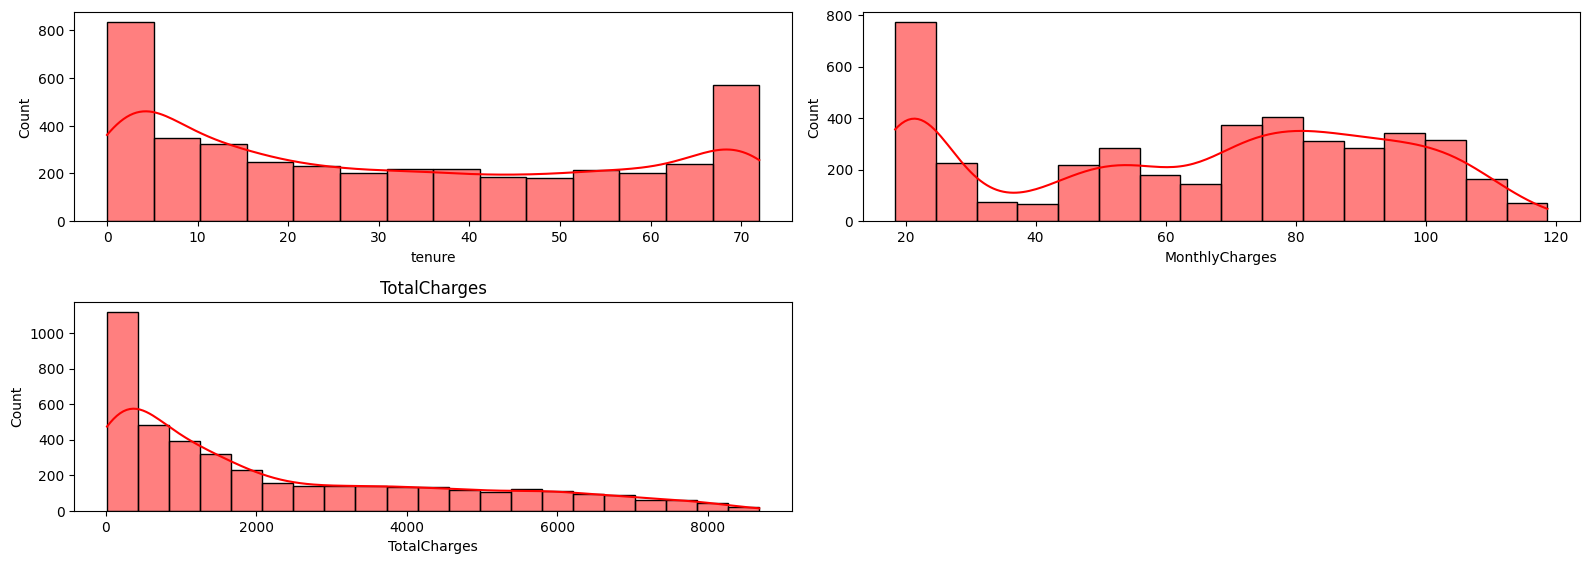

In [41]:
plt.figure(figsize=(16,14))
for i,col in enumerate(X_train_num,1):
  plt.subplot(5,2,i)
  sns.histplot(data=X_train_num[col],kde=True,color="red")
plt.title(col)
plt.tight_layout()
plt.show()

#Simple Imputer use for handling missing values in total charges column

In [42]:
num_missing_cols = X_train_num.columns[
    X_train_num.isna().any()
]
num_missing_cols

# Impute only numerical columns that contain missing values
if len(num_missing_cols) > 0:
    num_imputer = SimpleImputer(strategy="median")

    X_train_num[num_missing_cols] = num_imputer.fit_transform(
        X_train_num[num_missing_cols]
    )

    X_test_num[num_missing_cols] = num_imputer.transform(
        X_test_num[num_missing_cols]
    )

### Apply the training-fitted imputer to validation data


In [43]:
if len(num_missing_cols) > 0:
    X_val_num[num_missing_cols] = num_imputer.transform(
        X_val_num[num_missing_cols]
    )

print("Validation numerical missing values:", X_val_num.isna().sum().sum())

Validation numerical missing values: 0


In [44]:
X_train_num.isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,0


#Outlier Handling no need to remove its a classification task

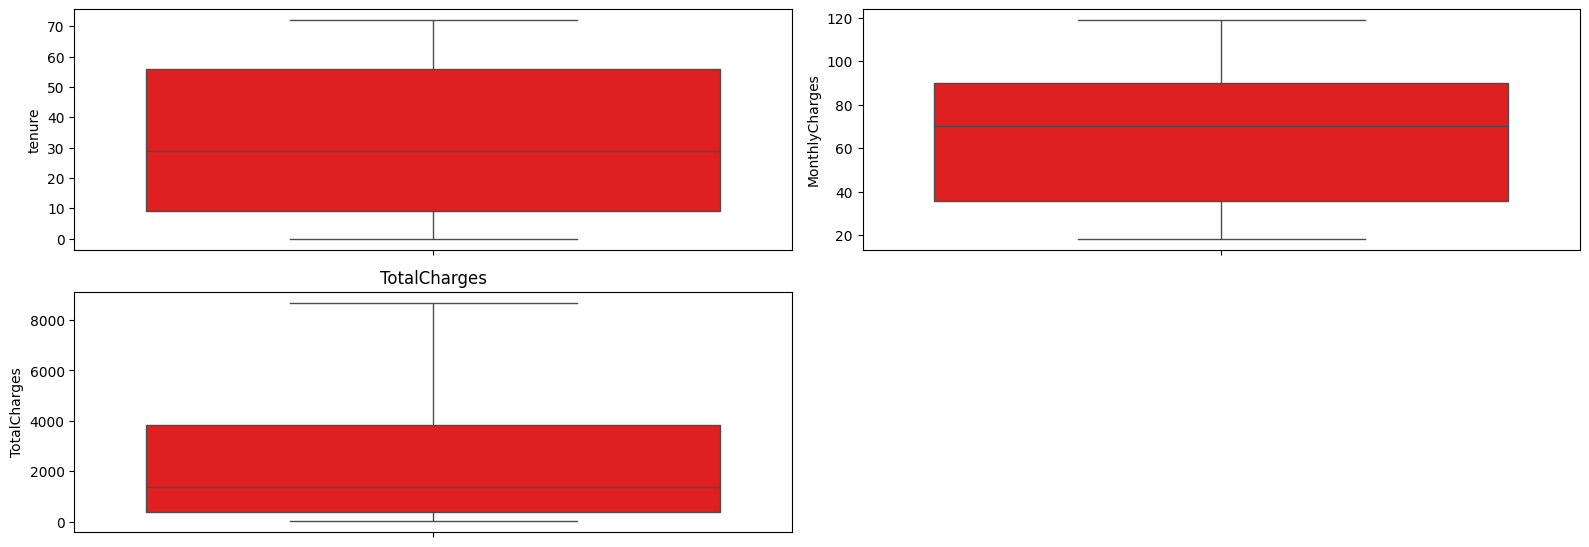

In [46]:
plt.figure(figsize=(16,14))
for i,col in enumerate(X_train_num,1):
  plt.subplot(5,2,i)
  sns.boxplot(data=X_train_num[col],color="red")
plt.title(col)
plt.tight_layout()
plt.show()

#Scaling for numerical columns

In [47]:
scaler=StandardScaler()
X_train_scale=scaler.fit_transform(X_train_num)
X_test_scale=scaler.transform(X_test_num)

### Scale validation numerical columns


In [48]:
X_val_scale = scaler.transform(X_val_num)

In [49]:
X_train_new=pd.DataFrame(X_train_scale,columns=X_train_num.columns,index=X_train.index)
X_test_new=pd.DataFrame(X_test_scale,columns=X_test_num.columns,index=X_test.index)

### Convert validation scaled data into a DataFrame

In [50]:
X_val_new = pd.DataFrame(
    X_val_scale,
    columns=X_val_num.columns,
    index=X_val.index
)

print("Validation numerical shape:", X_val_new.shape)

Validation numerical shape: (1409, 3)


In [51]:
print("Numerical columns on train data scaling shape:",X_train_new.shape)
print("Numerical columns on test data scaling shape:",X_test_new.shape)

Numerical columns on train data scaling shape: (4225, 3)
Numerical columns on test data scaling shape: (1409, 3)


In [52]:
X_train_new.head()

,tenure,MonthlyCharges,TotalCharges
2312,-0.579543,-1.489929,-0.827089
5227,-1.025518,1.047953,-0.722699
6404,0.798927,1.484829,1.512012
88,0.555668,-1.494931,-0.596561
6496,0.312408,1.236377,0.789990


#Encoding for categorical columns

In [53]:
for col in X_train_cat:
  print(col)
  print("Unique values is:",X_train_cat[col].unique())
  print("-" * 40)

gender
Unique values is: ['Male' 'Female']
----------------------------------------
Partner
Unique values is: ['No' 'Yes']
----------------------------------------
Dependents
Unique values is: ['No' 'Yes']
----------------------------------------
PhoneService
Unique values is: ['Yes' 'No']
----------------------------------------
MultipleLines
Unique values is: ['No' 'Yes' 'No phone service']
----------------------------------------
InternetService
Unique values is: ['No' 'Fiber optic' 'DSL']
----------------------------------------
OnlineSecurity
Unique values is: ['No internet service' 'No' 'Yes']
----------------------------------------
OnlineBackup
Unique values is: ['No internet service' 'No' 'Yes']
----------------------------------------
DeviceProtection
Unique values is: ['No internet service' 'No' 'Yes']
----------------------------------------
TechSupport
Unique values is: ['No internet service' 'No' 'Yes']
----------------------------------------
StreamingTV
Unique values is

#Encoding for Categorical columns

## Use ordinal Encoder for Contract and all other categorical columns used One hot Encoder

In [54]:
ordinal_list = ['Contract']

nominal_cols = []
ordinal_cols = []

for col in X_train_cat:
    if col in ordinal_list:
        ordinal_cols.append(col)
    else:
        nominal_cols.append(col)
nominal_cols.remove('SeniorCitizen')
print("Nominal Columns:", nominal_cols)
print("Ordinal Columns:", ordinal_cols)

Nominal Columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod']
Ordinal Columns: ['Contract']


In [55]:
encoder_ord=ordinal = OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']],dtype=int)
X_train_cat_ord=pd.DataFrame(
    encoder_ord.fit_transform(X_train_cat[ordinal_cols]),
    columns=ordinal_cols,
    index=X_train.index)

X_test_cat_ord=pd.DataFrame(encoder_ord.transform(X_test_cat[ordinal_cols]),columns=ordinal_cols,index=X_test.index)

### Ordinal encode validation data
The Contract encoder was fitted on training data. We apply the same category order to validation data.

In [56]:
X_val_cat_ord = pd.DataFrame(
    encoder_ord.transform(X_val_cat[ordinal_cols]),
    columns=ordinal_cols,
    index=X_val.index
)

In [57]:
X_train_cat_ord.head()


,Contract
2312,1
5227,0
6404,2
88,2
6496,0


In [58]:
encoder_hot=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=int)

X_train_cat_hot = pd.DataFrame(encoder_hot.fit_transform(X_train_cat[nominal_cols]),
                               columns=encoder_hot.get_feature_names_out(nominal_cols),
                               index=X_train.index)
X_test_cat_hot=pd.DataFrame(encoder_hot.transform(X_test_cat[nominal_cols]),
                            columns=encoder_hot.get_feature_names_out(nominal_cols),
                            index=X_test.index)

### One-hot encode validation data


In [59]:
X_val_cat_hot = pd.DataFrame(
    encoder_hot.transform(X_val_cat[nominal_cols]),
    columns=encoder_hot.get_feature_names_out(nominal_cols),
    index=X_val.index
)

In [60]:
X_train_cat_hot.head()

,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2312,0,1,1,0,1,0,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,1
5227,0,1,1,0,1,0,0,1,0,0,1,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0
6404,0,1,1,0,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0
88,1,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1
6496,0,1,0,1,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0


In [61]:
#concating two categorical columns and the senior citizen column
X_train_cat_final=pd.concat([X_train_cat_ord,X_train_cat_hot,X_train_cat[["SeniorCitizen"]]],axis=1)
X_test_cat_final=pd.concat([X_test_cat_ord,X_test_cat_hot,X_test_cat[["SeniorCitizen"]]],axis=1)

### Combine validation categorical columns

In [62]:
X_val_cat_final = pd.concat(
    [X_val_cat_ord, X_val_cat_hot, X_val_cat[["SeniorCitizen"]]],
    axis=1
)

In [63]:
X_train_cat_final.head()


,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen
2312,1,0,1,1,0,1,0,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,1,0
5227,0,0,1,1,0,1,0,0,1,0,0,1,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,0
6404,2,0,1,1,0,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,0
88,2,1,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0
6496,0,0,1,0,1,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,1


In [64]:
#concating numerical and categorical columns
X_train_final=pd.concat([X_train_cat_final,X_train_new],axis=1)
X_test_final=pd.concat([X_test_cat_final,X_test_new],axis=1)

### Combine validation numerical and categorical columns

In [65]:
X_val_final = pd.concat(
    [X_val_cat_final, X_val_new],
    axis=1
)

print("Validation final shape:", X_val_final.shape)
print("Validation missing values:", X_val_final.isna().sum().sum())

Validation final shape: (1409, 43)
Validation missing values: 0


In [66]:
X_train_final.head()

,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
2312,1,0,1,1,0,1,0,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,1,0,-0.579543,-1.489929,-0.827089
5227,0,0,1,1,0,1,0,0,1,0,0,1,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,0,-1.025518,1.047953,-0.722699
6404,2,0,1,1,0,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,0,0.798927,1.484829,1.512012
88,2,1,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0.555668,-1.494931,-0.596561
6496,0,0,1,0,1,1,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,1,0.312408,1.236377,0.789990


In [67]:
print(X_train_final.shape)
print(X_test_final.shape)

print(X_train_final.isna().sum().sum())
print(X_test_final.isna().sum().sum())


(4225, 43)
(1409, 43)
0
0


In [68]:
y_train.value_counts()


,count
Churn,
No,3104
Yes,1121


Label Encoder for target value

In [69]:
encoder_lb=LabelEncoder()
y_train_enc=pd.Series(encoder_lb.fit_transform(y_train),
                      index=y_train.index,
                      name="Churn")
y_test_enc=pd.Series(encoder_lb.transform(y_test),
                     index=y_test.index,
                     name="Churn")

### Encode validation target
Use the LabelEncoder already fitted on training labels. Do not fit it again on validation data.

In [70]:
y_val_enc = pd.Series(
    encoder_lb.transform(y_val),
    index=y_val.index,
    name="Churn"
)

print("Validation target distribution:")
print(y_val_enc.value_counts())

Validation target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [71]:
y_train_enc.value_counts()

,count
Churn,
0,3104
1,1121


In [72]:
y_train.value_counts(normalize=True)*100

,proportion
Churn,
No,73.467456
Yes,26.532544


#Class Imbalanced

In [73]:
#Smote applied only to training data
smote=SMOTE(random_state=42)
X_train_bal,y_train_bal=smote.fit_resample(
    X_train_final,y_train_enc)

X_train_bal_df=pd.DataFrame(X_train_bal,columns=X_train_final.columns)

y_train_bal_df=pd.Series(y_train_bal, name=y_train_enc.name)

print("Before SMOTE:")
print(y_train_enc.value_counts())


Before SMOTE:
Churn
0    3104
1    1121
Name: count, dtype: int64


In [74]:

print("\nAfter SMOTE:")
print(y_train_bal_df.value_counts())

print("\nBalanced training shape:", X_train_bal_df.shape)


After SMOTE:
Churn
0    3104
1    3104
Name: count, dtype: int64

Balanced training shape: (6208, 43)


#Features Selection -- Correlation Matrix

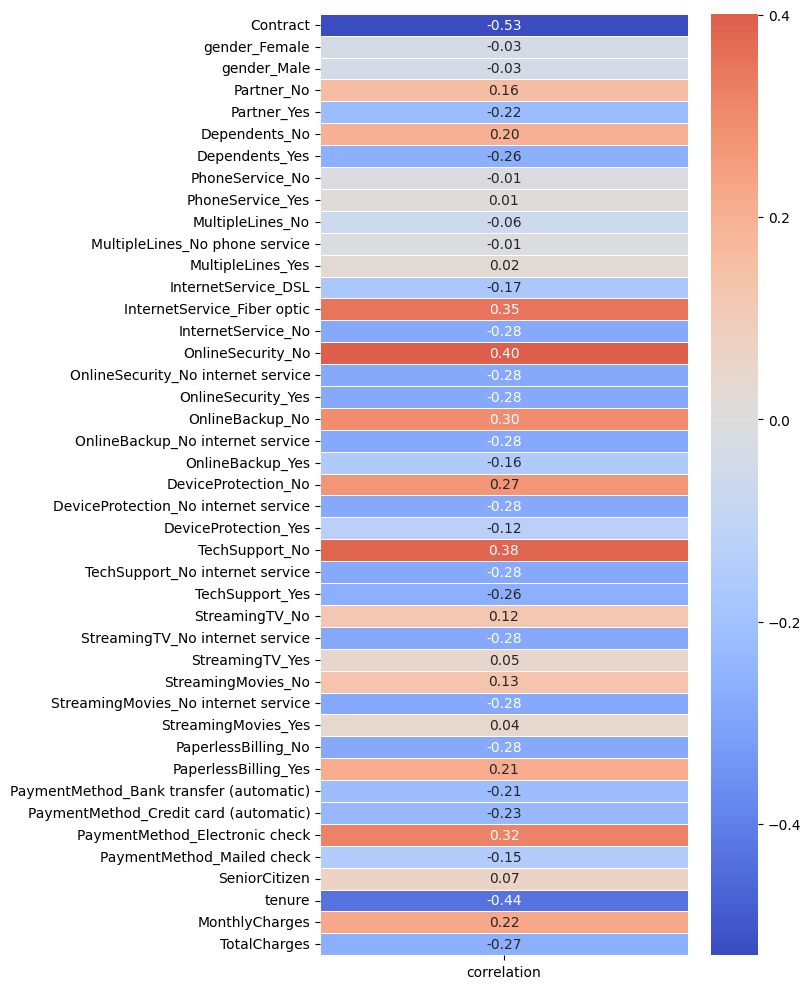

In [75]:
corr_target = X_train_bal_df.corrwith(y_train_bal_df).to_frame(name="correlation")



plt.figure(figsize=(8,10))

sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5,
    center=0
)
plt.tight_layout()
plt.show()

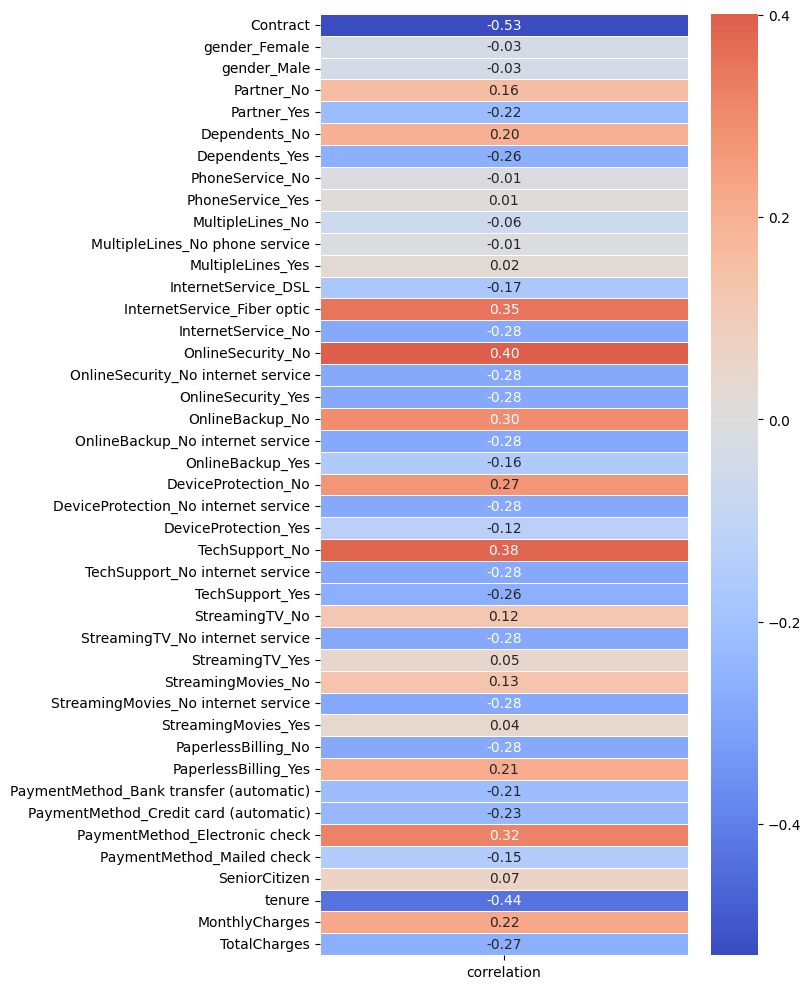

In [76]:
corr_target = X_train_bal_df.corrwith(pd.DataFrame(y_train_bal_df).iloc[:,0]).to_frame(name="correlation")


plt.figure(figsize=(8,10))

sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5,
    center=0
)
plt.tight_layout()
plt.show()

In [77]:


corr_target = X_train_bal_df.corrwith(y_train_bal_df).round(2)
abs_corr = corr_target.abs()

#  Define thresholds from 0.3 to 0.8
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
selected_cols = []

for low, high in zip(thresholds, thresholds[1:]):
    in_range = abs_corr[(abs_corr >= low) & (abs_corr < high)]

    if not in_range.empty:
        best_col = in_range.idxmax()
        selected_cols.append(best_col)
        print(f"Range {low}-{high}: {best_col} ({corr_target[best_col]:.2f})")
    else:
        print(f"Range {low}-{high}: None")

print("\nSelected columns:", selected_cols)


Range 0.3-0.4: TechSupport_No (0.38)
Range 0.4-0.5: tenure (-0.44)
Range 0.5-0.6: Contract (-0.53)
Range 0.6-0.7: None
Range 0.7-0.8: None

Selected columns: ['TechSupport_No', 'tenure', 'Contract']


In [78]:
features_selected=['TechSupport_No', 'tenure', 'Contract']
X_train_selected = X_train_bal_df[features_selected]
X_test_selected = X_test_final[features_selected]

In [79]:
corr_target_original = X_train_final.corrwith(y_train_enc).round(2)
abs_corr_original = corr_target_original.abs()

thresholds_original = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
selected_cols_original = []

for low, high in zip(thresholds_original, thresholds_original[1:]):
    in_range = abs_corr_original[
        (abs_corr_original >= low) & (abs_corr_original < high)
    ]

    if not in_range.empty:
        best_col = in_range.idxmax()
        selected_cols_original.append(best_col)
        print(
            f"Range {low}-{high}: {best_col} "
            f"({corr_target_original[best_col]:.2f})"
        )
    else:
        print(f"Range {low}-{high}: None")


if len(selected_cols_original) > 0:
    features_selected = selected_cols_original

print("\nFinal selected features:", features_selected)


X_train_selected = X_train_bal_df[features_selected].copy()
X_val_selected = X_val_final[features_selected].copy()
X_test_selected = X_test_final[features_selected].copy()

print("Selected training shape:", X_train_selected.shape)
print("Selected validation shape:", X_val_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

Range 0.3-0.4: OnlineSecurity_No (0.35)
Range 0.4-0.5: Contract (-0.41)
Range 0.5-0.6: None
Range 0.6-0.7: None
Range 0.7-0.8: None

Final selected features: ['OnlineSecurity_No', 'Contract']
Selected training shape: (6208, 2)
Selected validation shape: (1409, 2)
Selected testing shape: (1409, 2)


In [80]:
X_train_selected.head()

,OnlineSecurity_No,Contract
0,0,1
1,1,0
2,0,2
3,0,2
4,0,0


#Model Selection Logistic Regression

In [81]:
log_reg=LogisticRegression()
#fit and evaluate both on training input and output
log_reg.fit(X_train_selected, y_train_bal_df)

#predict  only on input find how much output predict
log_reg_pred=log_reg.predict(X_test_selected)

In [82]:
# Generate predictions on the training data
log_reg_train_pred = log_reg.predict(X_train_selected)

# Calculate accuracy score on training data output
lr_train_acc = accuracy_score(y_train_bal_df, log_reg_train_pred)

print(f"Logistic Regression Training Accuracy: {lr_train_acc:.4f}")

Logistic Regression Training Accuracy: 0.7505


In [83]:
# Calculate accuracy score on testing data ouptut only and predicred using test data
lr_test_acc = accuracy_score(y_test_enc, log_reg_pred)
print(f"Logistic Regression Test Accuracy: {lr_test_acc:.4f}")

Logistic Regression Test Accuracy: 0.6529


In [84]:
#Calculate the confusion matrix for the logistic Regression model on the test set output only and predicred using test data
lr_cm=confusion_matrix(y_test_enc,log_reg_pred)
print("Confusion Matrix")
print(lr_cm)

Confusion Matrix
[[591 444]
 [ 45 329]]


In [85]:
print(classification_report(y_test_enc, log_reg_pred))

              precision    recall  f1-score   support

           0       0.93      0.57      0.71      1035
           1       0.43      0.88      0.57       374

    accuracy                           0.65      1409
   macro avg       0.68      0.73      0.64      1409
weighted avg       0.80      0.65      0.67      1409



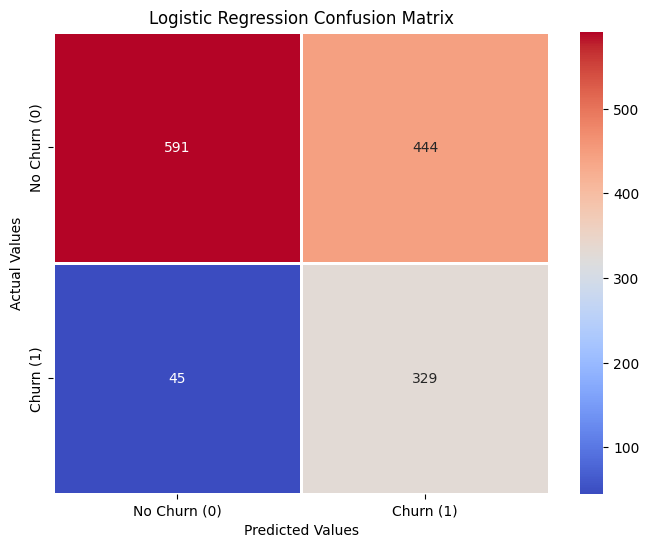

In [87]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidth=1,
    xticklabels=["No Churn (0)", "Churn (1)"],
    yticklabels=["No Churn (0)", "Churn (1)"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

## Logistic Regression: Decision Threshold Analysis



In [89]:
from sklearn.metrics import precision_score, recall_score, f1_score
# Probability that each validation customer belongs to Churn (class 1)
y_val_prob = log_reg.predict_proba(X_val_selected)[:, 1]

thresholds = [0.3, 0.5, 0.7]
threshold_results = []

for threshold in thresholds:
    y_val_threshold_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append([
        threshold,
        precision_score(y_val_enc, y_val_threshold_pred, zero_division=0),
        recall_score(y_val_enc, y_val_threshold_pred, zero_division=0),
        f1_score(y_val_enc, y_val_threshold_pred, zero_division=0)
    ])

threshold_results_df = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "Validation Precision",
             "Validation Recall", "Validation F1-score"]
)

threshold_results_df

,Threshold,Validation Precision,Validation Recall,Validation F1-score
0,0.3,0.384358,0.919786,0.542159
1,0.5,0.417526,0.866310,0.563478
2,0.7,0.497143,0.697861,0.580645


In [90]:
best_threshold = float(
    threshold_results_df.loc[
        threshold_results_df["Validation F1-score"].idxmax(),
        "Threshold"
    ]
)

print("Best threshold based on validation F1-score:", best_threshold)

Best threshold based on validation F1-score: 0.7


### Final Logistic Regression evaluation using the selected threshold

Selected threshold: 0.7
Accuracy: 0.7366926898509581
Precision: 0.5028462998102466
Recall: 0.7085561497326203
F1-score: 0.5882352941176471


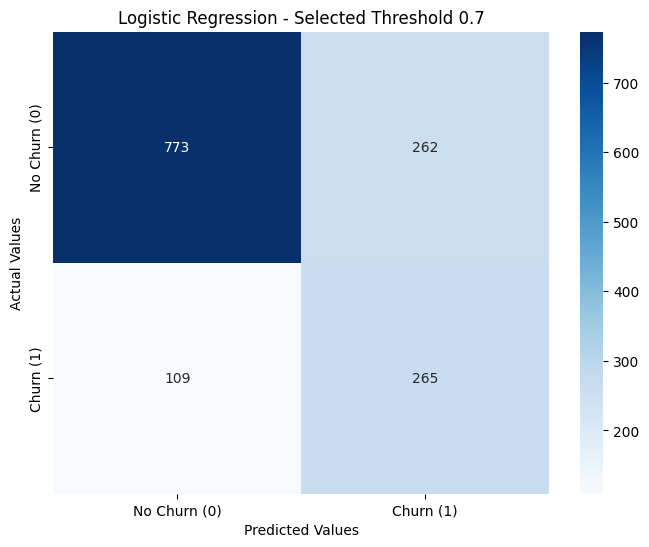

              precision    recall  f1-score   support

    No Churn       0.88      0.75      0.81      1035
       Churn       0.50      0.71      0.59       374

    accuracy                           0.74      1409
   macro avg       0.69      0.73      0.70      1409
weighted avg       0.78      0.74      0.75      1409



In [91]:
# Test probabilities are used only after the threshold has been selected.
y_test_prob = log_reg.predict_proba(X_test_selected)[:, 1]
lr_final_pred = (y_test_prob >= best_threshold).astype(int)

print("Selected threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_test_enc, lr_final_pred))
print("Precision:", precision_score(y_test_enc, lr_final_pred, zero_division=0))
print("Recall:", recall_score(y_test_enc, lr_final_pred, zero_division=0))
print("F1-score:", f1_score(y_test_enc, lr_final_pred, zero_division=0))

lr_final_cm = confusion_matrix(y_test_enc, lr_final_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    lr_final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn (0)", "Churn (1)"],
    yticklabels=["No Churn (0)", "Churn (1)"]
)
plt.title(f"Logistic Regression - Selected Threshold {best_threshold}")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

print(classification_report(
    y_test_enc, lr_final_pred,
    target_names=["No Churn", "Churn"]
))

#KNN neigbour Classifier

In [92]:
#fit and evaluate
knn=KNeighborsClassifier(n_neighbors=3) #check the value of parameters by trial and error method
#fit on training (both train output and input)
knn.fit(X_train_selected,y_train_bal_df)
#Predict on test data
knn_pred=knn.predict(X_test_selected)

In [93]:
# Generate predictions on the training data
knn_reg_train_pred = knn.predict(X_train_selected)

# Calculate accuracy score on training data
lr_train_acc = accuracy_score(y_train_bal_df, knn_reg_train_pred)

print(f"Knn Training Accuracy: {lr_train_acc:.4f}")

Knn Training Accuracy: 0.7505


In [94]:
lr_test_acc=accuracy_score(y_test_enc,knn_pred)
print(f"Knn Testing Accuracy: {lr_test_acc:.4f}")

Knn Testing Accuracy: 0.6529


In [95]:
#Calculate the confusion matrix for the logistic Regression model on the test set
lr_knn=confusion_matrix(y_test_enc,knn_pred)
print("Confusion Matrix")
print(lr_knn)

Confusion Matrix
[[591 444]
 [ 45 329]]


In [96]:
print(classification_report(y_test_enc, knn_pred))

              precision    recall  f1-score   support

           0       0.93      0.57      0.71      1035
           1       0.43      0.88      0.57       374

    accuracy                           0.65      1409
   macro avg       0.68      0.73      0.64      1409
weighted avg       0.80      0.65      0.67      1409



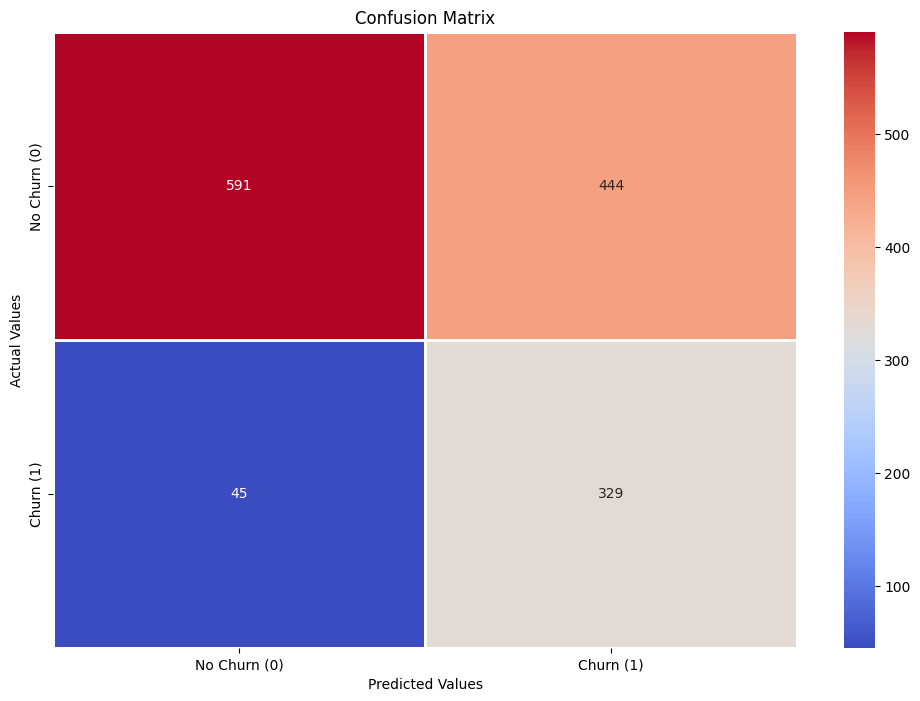

In [98]:
plt.figure(figsize=(12,8))

sns.heatmap(
    lr_knn,
    annot=True,
    fmt='d',
    cmap="coolwarm",
    linewidth=1,
    xticklabels=["No Churn (0)", "Churn (1)"],
    yticklabels=["No Churn (0)", "Churn (1)"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

## KNN: Select the Best K Using Validation F1-score



In [99]:
k_values = [3, 5, 7, 9, 11, 15, 21]
knn_validation_results = []

for k in k_values:
    knn_validation_model = KNeighborsClassifier(n_neighbors=k)
    knn_validation_model.fit(X_train_selected, y_train_bal_df)

    y_val_knn_pred = knn_validation_model.predict(X_val_selected)
    val_f1 = f1_score(y_val_enc, y_val_knn_pred, zero_division=0)

    knn_validation_results.append([k, val_f1])
    print("K:", k, "Validation F1-score:", round(val_f1, 4))

knn_validation_df = pd.DataFrame(
    knn_validation_results,
    columns=["K", "Validation F1-score"]
)

knn_validation_df

K: 3 Validation F1-score: 0.5635
K: 5 Validation F1-score: 0.5635
K: 7 Validation F1-score: 0.5806
K: 9 Validation F1-score: 0.5806
K: 11 Validation F1-score: 0.5806
K: 15 Validation F1-score: 0.5806
K: 21 Validation F1-score: 0.5806


,K,Validation F1-score
0,3,0.563478
1,5,0.563478
2,7,0.580645
3,9,0.580645
4,11,0.580645
5,15,0.580645
6,21,0.580645


In [100]:
best_k = int(
    knn_validation_df.loc[
        knn_validation_df["Validation F1-score"].idxmax(), "K"
    ]
)

print("Best K based on validation F1-score:", best_k)

Best K based on validation F1-score: 7


### Train and evaluate the final KNN model

Best K: 7
KNN Test Accuracy: 0.7366926898509581
KNN Test Precision: 0.5028462998102466
KNN Test Recall: 0.7085561497326203
KNN Test F1-score: 0.5882352941176471


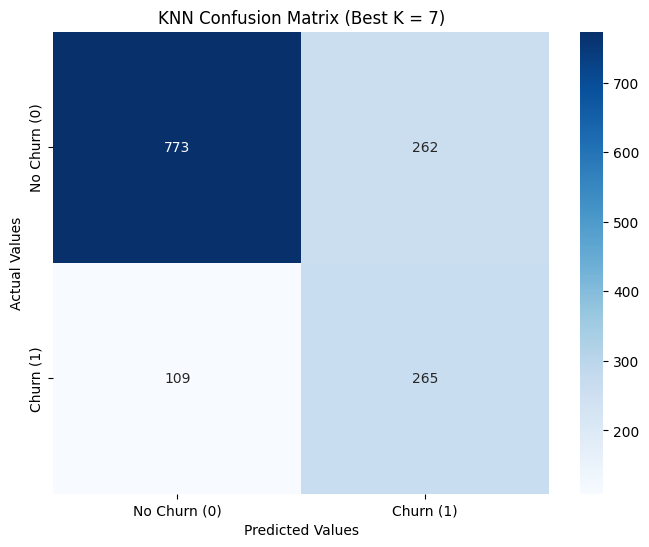

              precision    recall  f1-score   support

    No Churn       0.88      0.75      0.81      1035
       Churn       0.50      0.71      0.59       374

    accuracy                           0.74      1409
   macro avg       0.69      0.73      0.70      1409
weighted avg       0.78      0.74      0.75      1409



In [101]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_selected, y_train_bal_df)

knn_best_pred = knn_best.predict(X_test_selected)

print("Best K:", best_k)
print("KNN Test Accuracy:", accuracy_score(y_test_enc, knn_best_pred))
print("KNN Test Precision:", precision_score(y_test_enc, knn_best_pred, zero_division=0))
print("KNN Test Recall:", recall_score(y_test_enc, knn_best_pred, zero_division=0))
print("KNN Test F1-score:", f1_score(y_test_enc, knn_best_pred, zero_division=0))

knn_best_cm = confusion_matrix(y_test_enc, knn_best_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    knn_best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn (0)", "Churn (1)"],
    yticklabels=["No Churn (0)", "Churn (1)"]
)
plt.title(f"KNN Confusion Matrix (Best K = {best_k})")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

print(classification_report(
    y_test_enc, knn_best_pred,
    target_names=["No Churn", "Churn"]
))

In [102]:
model_comparison = pd.DataFrame({
    "Model": ["KNN", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test_enc, knn_best_pred),
        accuracy_score(y_test_enc, lr_final_pred)
    ],
    "Precision": [
        precision_score(y_test_enc, knn_best_pred, zero_division=0),
        precision_score(y_test_enc, lr_final_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_enc, knn_best_pred, zero_division=0),
        recall_score(y_test_enc, lr_final_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test_enc, knn_best_pred, zero_division=0),
        f1_score(y_test_enc, lr_final_pred, zero_division=0)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,KNN,0.736693,0.502846,0.708556,0.588235
1,Logistic Regression,0.736693,0.502846,0.708556,0.588235


1. Logistic Regression – Decision Threshold Analysis
I used predict_proba() to find the probability of each customer leaving the company. I tested three thresholds: 0.3, 0.5, and 0.7 to see how the predictions change. When the threshold is 0.3, more customers are predicted as likely to leave. At 0.5, the model uses its default threshold. At 0.7, the model predicts churn only when the probability is higher. I selected 0.7 because it gave the best F1-score on the validation data. With this threshold, the model achieved 73.67% accuracy, 50.28% precision, 70.86% recall, and 58.82% F1-score on the test data. This means the model can identify around 71% of the customers who actually leave the company.

2. Comparison of KNN and Logistic Regression
I compared both KNN and Logistic Regression to see which model gives better results. For KNN, I tried different K values and selected K = 7 because it gave the best F1-score on the validation data. For Logistic Regression, I selected 0.7 as the threshold. When I checked the test results, both models gave the same accuracy, precision, recall, and F1-score. So, both models performed equally in this case, and I cannot say that one is better than the other.

3. False Positive and False Negative Errors
A false positive means the model predicts that a customer will leave, but the customer actually stays. This may lead the company to give unnecessary discounts or offers to that customer. A false negative means the model predicts that a customer will stay, but the customer actually leaves. This can cause the company to lose a customer without knowing that they were planning to leave. In this problem, false negatives are important because the company wants to find customers who may leave and try to keep them or hire people with the talents if it doesnt find company have loss

So, reducing false negatives and improving Recall for the Churn class is important in this problem.